In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load dataset from the uploaded titanic.csv
df = pd.read_csv("titanic.csv")
df_original = df.copy()

print("Dataset 'titanic.csv' loaded successfully!")

Dataset 'titanic.csv' loaded successfully!


In [30]:
print(df.head())
print(df.tail())
print("Shape:", df.shape)
df.info()

   Unnamed: 0  PassengerId  Survived  Sex     Age      Fare  Pclass_1  \
0         791          792         0    1  0.2000  0.050749         0   
1         792          793         0    0  0.3500  0.135753         0   
2         793          794         0    1  0.3500  0.059914         1   
3         794          795         0    1  0.3125  0.015412         0   
4         795          796         0    1  0.4875  0.025374         0   

   Pclass_2  Pclass_3  Family_size  Title_1  Title_2  Title_3  Title_4  Emb_1  \
0         1         0          0.0        1        0        0        0      0   
1         0         1          1.0        0        0        0        1      0   
2         0         0          0.0        1        0        0        0      1   
3         0         1          0.0        1        0        0        0      0   
4         1         0          0.0        1        0        0        0      0   

   Emb_2  Emb_3  
0      0      1  
1      0      1  
2      0      0  
3 

In [31]:
print(df.isnull().sum())

Unnamed: 0     0
PassengerId    0
Survived       0
Sex            0
Age            0
Fare           0
Pclass_1       0
Pclass_2       0
Pclass_3       0
Family_size    0
Title_1        0
Title_2        0
Title_3        0
Title_4        0
Emb_1          0
Emb_2          0
Emb_3          0
dtype: int64


In [32]:
# Fill missing values in Age and Fare with median if any exist
if "Age" in df.columns:
    df["Age"] = df["Age"].fillna(df["Age"].median())
if "Fare" in df.columns:
    df["Fare"] = df["Fare"].fillna(df["Fare"].median())

print("Missing values handled:")
print(df.isnull().sum())

Missing values handled:
Unnamed: 0     0
PassengerId    0
Survived       0
Sex            0
Age            0
Fare           0
Pclass_1       0
Pclass_2       0
Pclass_3       0
Family_size    0
Title_1        0
Title_2        0
Title_3        0
Title_4        0
Emb_1          0
Emb_2          0
Emb_3          0
dtype: int64


In [33]:
print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Shape after removing duplicates:", df.shape)

Duplicates: 0
Shape after removing duplicates: (100, 17)


In [34]:
print("Survived target distribution:")
print(df["Survived"].value_counts())

print("\nSex distribution (1 = Male, 0 = Female):")
print(df["Sex"].value_counts())

Survived target distribution:
Survived
0    64
1    36
Name: count, dtype: int64

Sex distribution (1 = Male, 0 = Female):
Sex
1    65
0    35
Name: count, dtype: int64


In [35]:
# Validate and filter out any invalid targets if present
df = df[df["Survived"].isin([0, 1])].copy()
print("Data validated.")

Data validated.


In [36]:
# Check outliers for continuous variables Age and Fare
for col in ["Age", "Fare"]:
    if col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        print(f"{col} Outliers count:", ((df[col] < lower) | (df[col] > upper)).sum())

Age Outliers count: 7
Fare Outliers count: 10


In [37]:
# Clip outliers in Age and Fare using IQR capping
for col in ["Age", "Fare"]:
    if col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df[col] = df[col].clip(lower, upper)
print("Outliers in continuous numerical variables capped successfully!")

Outliers in continuous numerical variables capped successfully!


In [39]:
# Identify numerical features
num_cols = df.select_dtypes(include=np.number).columns.tolist()
print("Numerical columns:", num_cols)

Numerical columns: ['Unnamed: 0', 'PassengerId', 'Survived', 'Sex', 'Age', 'Fare', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Family_size', 'Title_1', 'Title_2', 'Title_3', 'Title_4', 'Emb_1', 'Emb_2', 'Emb_3']


In [40]:
# Convert categorical columns to dummy variables if there are any remaining object columns
cat_cols = df.select_dtypes(include="object").columns.tolist()
if cat_cols:
    df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
print("Processed dataset shape:", df.shape)

Processed dataset shape: (100, 17)


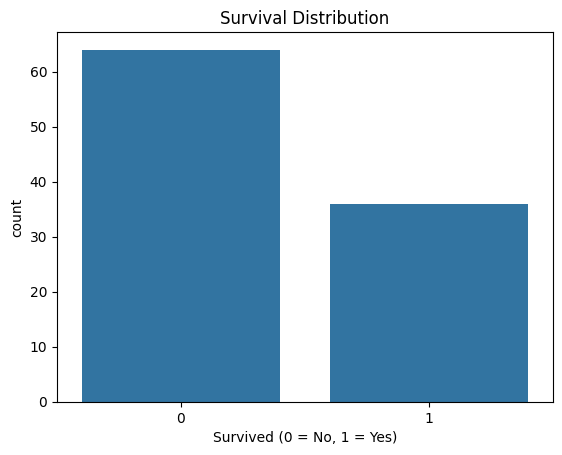

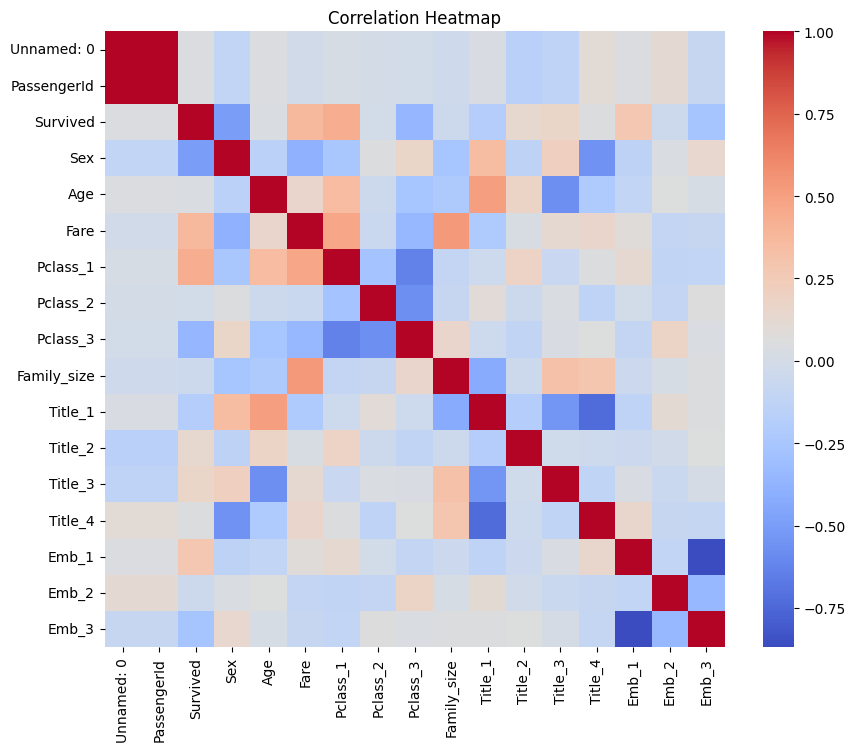

In [41]:
sns.countplot(data=df_original, x="Survived")
plt.title("Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), cmap="coolwarm", annot=False)
plt.title("Correlation Heatmap")
plt.show()

In [42]:
# Select features and target variables
# Dropping Target, PassengerId, and any identifier columns like Unnamed or index
ignore_cols = ["Survived", "PassengerId", "Unnamed: 0"]
X = df.drop(columns=[col for col in ignore_cols if col in df.columns])
y = df["Survived"]

print("Features selected:", X.columns.tolist())
print("Target variable distribution:\n", y.value_counts())

Features selected: ['Sex', 'Age', 'Fare', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Family_size', 'Title_1', 'Title_2', 'Title_3', 'Title_4', 'Emb_1', 'Emb_2', 'Emb_3']
Target variable distribution:
 Survived
0    64
1    36
Name: count, dtype: int64


In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Train set size:", X_train.shape)
print("Test set size:", X_test.shape)

Train set size: (80, 14)
Test set size: (20, 14)


In [44]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [45]:
# Train logistic regression model
model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Model trained successfully!")

Model trained successfully!


In [46]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy, 4))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.75
Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.77      0.80        13
           1       0.62      0.71      0.67         7

    accuracy                           0.75        20
   macro avg       0.73      0.74      0.73        20
weighted avg       0.76      0.75      0.75        20



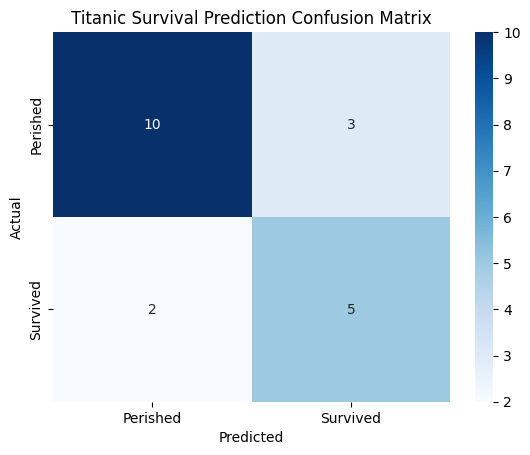

In [47]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Perished", "Survived"],
    yticklabels=["Perished", "Survived"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Titanic Survival Prediction Confusion Matrix")
plt.show()

In [48]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(comparison.head(10))



   Actual  Predicted
0       0          0
1       0          0
2       1          1
3       0          0
4       0          1
5       1          1
6       0          0
7       0          0
8       1          1
9       0          1
